# NOTEBOOK 03: MACHINE LEARNING MODEL TRAINING & BENCHMARKING
We train and benchmark 3 classical ML models:
1. **Logistic Regression** (with cost-sensitive class balancing)
2. **Random Forest Classifier** (ensemble of decision trees)
3. **XGBoost Classifier** (extreme gradient boosted trees)


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    roc_curve, precision_recall_curve, confusion_matrix
)

sys.path.append(os.path.join("..", "training_scripts"))
from data_loader import prepare_splits, FEATURE_COLUMNS

data = prepare_splits()
X_train, y_train = data['X_train'], data['y_train']
X_val, y_val = data['X_val'], data['y_val']
X_test, y_test = data['X_test'], data['y_test']


### 3.1 Model Training & Validation Benchmark

In [2]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.1, random_state=42, eval_metric="logloss")
}

val_results = []
fitted_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    fitted_models[name] = model
    y_pred = model.predict(X_val)
    y_prob = model.predict_proba(X_val)[:, 1] if hasattr(model, "predict_proba") else y_pred
    
    val_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
        "F1-Score": f1_score(y_val, y_pred),
        "ROC-AUC": roc_auc_score(y_val, y_prob)
    })

res_df = pd.DataFrame(val_results)
res_df


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8873,0.421352,0.872941,0.568365,0.961293
1,Random Forest,0.9712,1.000000,0.661176,0.796034,0.974804
2,XGBoost,0.9714,0.989583,0.670588,0.799439,0.980428


### 3.2 Visual Performance Comparison (Grouped Bar Chart)

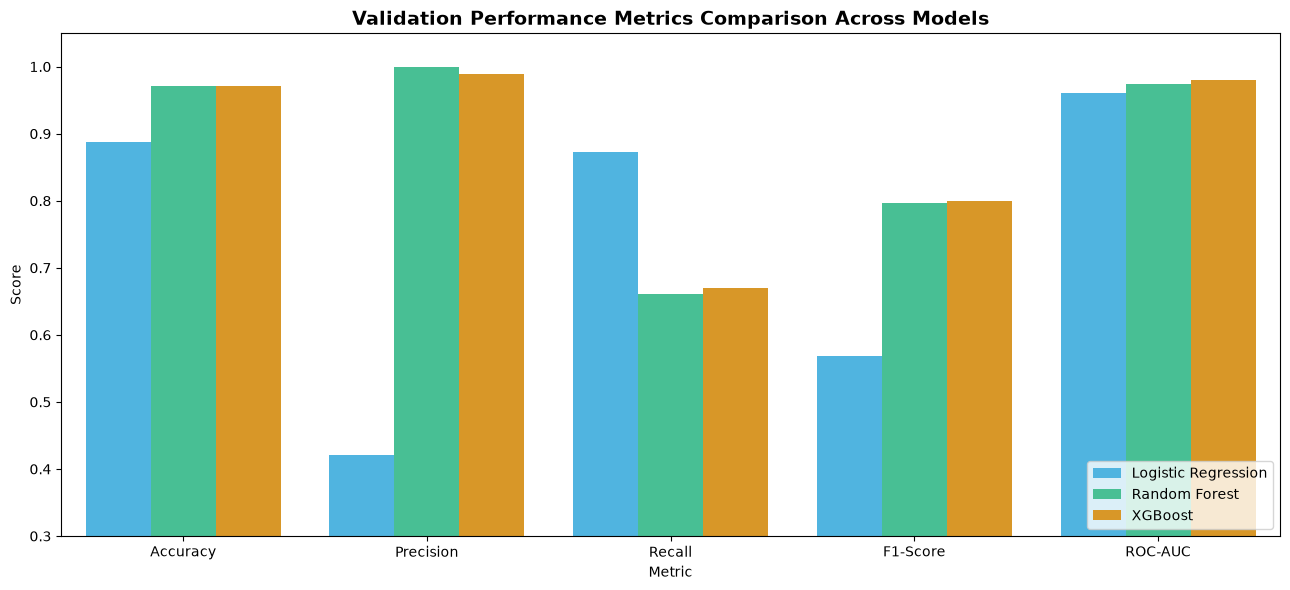

In [3]:
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
melted_df = pd.melt(res_df, id_vars=['Model'], value_vars=metrics, var_name='Metric', value_name='Score')

plt.figure(figsize=(13, 6))
sns.barplot(data=melted_df, x='Metric', y='Score', hue='Model', palette=['#38bdf8', '#34d399', '#f59e0b'])
plt.ylim(0.3, 1.05)
plt.title("Validation Performance Metrics Comparison Across Models", fontsize=14, fontweight='bold')
plt.ylabel("Score")
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()


### 3.3 Receiver Operating Characteristic (ROC) & Precision-Recall Curves

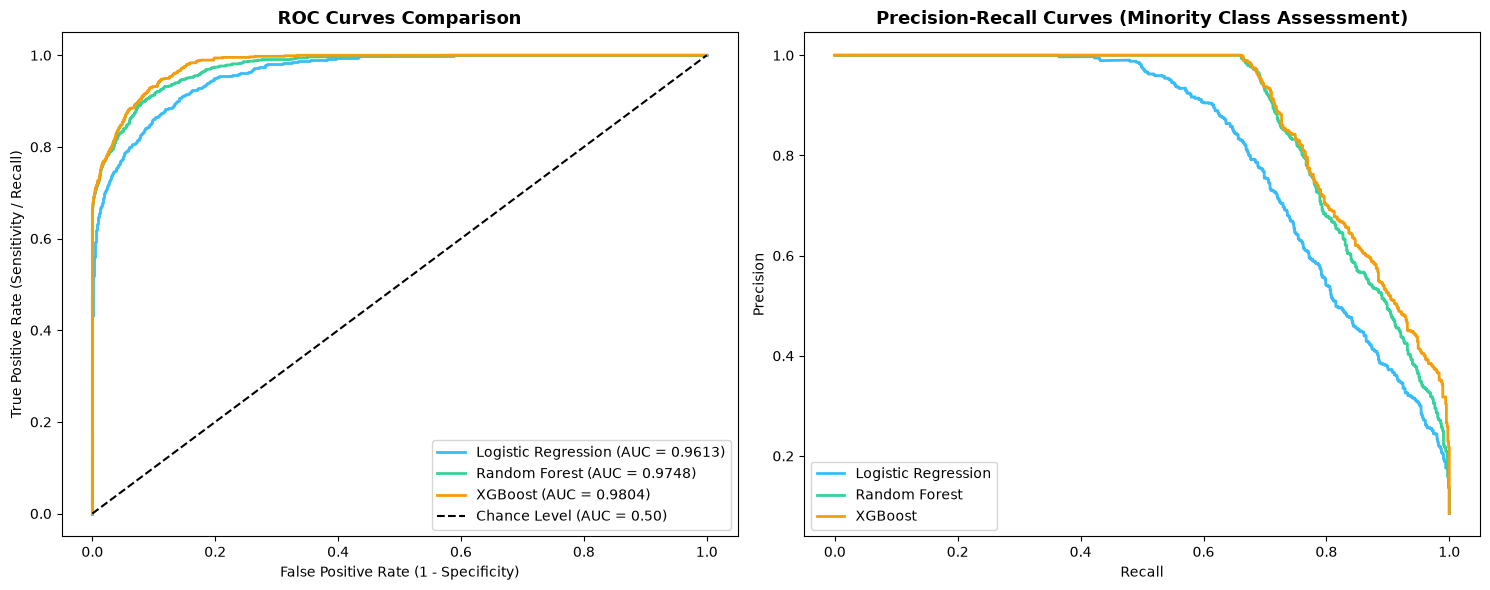

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

colors = {'Logistic Regression': '#38bdf8', 'Random Forest': '#34d399', 'XGBoost': '#f59e0b'}

# ROC Curves
for name, model in fitted_models.items():
    y_prob = model.predict_proba(X_val)[:, 1]
    fpr, tpr, _ = roc_curve(y_val, y_prob)
    auc_score = roc_auc_score(y_val, y_prob)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.4f})", color=colors[name], linewidth=2)

axes[0].plot([0, 1], [0, 1], 'k--', label="Chance Level (AUC = 0.50)")
axes[0].set_title("ROC Curves Comparison", fontsize=13, fontweight='bold')
axes[0].set_xlabel("False Positive Rate (1 - Specificity)")
axes[0].set_ylabel("True Positive Rate (Sensitivity / Recall)")
axes[0].legend(loc='lower right')

# Precision-Recall Curves (crucial for imbalanced datasets)
for name, model in fitted_models.items():
    y_prob = model.predict_proba(X_val)[:, 1]
    prec, rec, _ = precision_recall_curve(y_val, y_prob)
    axes[1].plot(rec, prec, label=f"{name}", color=colors[name], linewidth=2)

axes[1].set_title("Precision-Recall Curves (Minority Class Assessment)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc='lower left')

plt.tight_layout()
plt.show()


### 3.4 Confusion Matrix Comparison on Validation Set

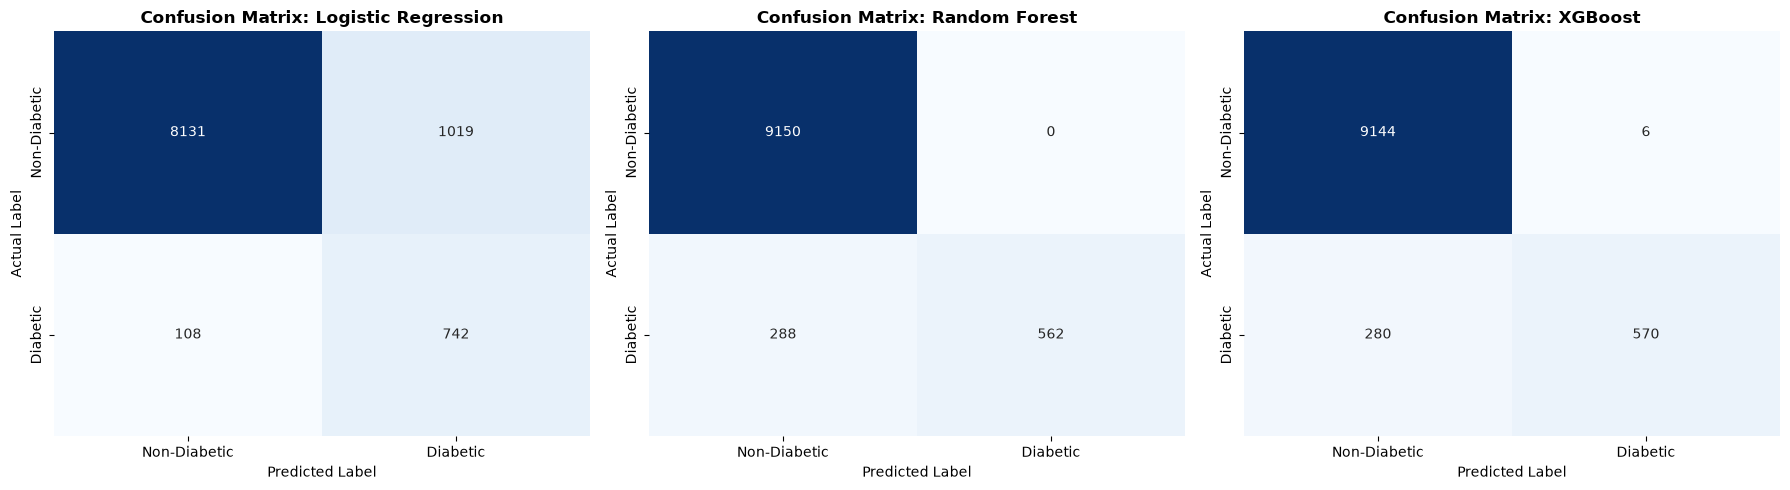

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (name, model) in enumerate(fitted_models.items()):
    y_pred = model.predict(X_val)
    cm = confusion_matrix(y_val, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False,
                xticklabels=['Non-Diabetic', 'Diabetic'], yticklabels=['Non-Diabetic', 'Diabetic'])
    axes[idx].set_title(f"Confusion Matrix: {name}", fontsize=12, fontweight='bold')
    axes[idx].set_xlabel("Predicted Label")
    axes[idx].set_ylabel("Actual Label")

plt.tight_layout()
plt.show()
